# 02 – Payment formats, currencies and same-bank payments
Question: are some payment formats, currencies or bank combinations much more likely to be laundering?
Splits used: **train only**.
Methods: laundering rate with 95% Wilson intervals, lift, chi-square test of independence, Cramér's V.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

from src.analysis.data import load_eda_frame
from src.analysis.stats import rate_table, chi_square_test

pd.set_option("display.max_columns", 30)
train = load_eda_frame()          # train only (the default)
overall_rate = 100 * train["is_laundering"].mean()
print(f"Train rows: {len(train):,}   overall laundering rate: {overall_rate:.4f}%")

Train rows: 3,046,861   overall laundering rate: 0.0754%


In [2]:
def plot_rates(table, title, highlight=None):
    """Horizontal bars of laundering rate per category, with 95% CI whiskers
    and a dashed line at the overall train rate."""
    t = table.sort_values("rate_%")
    colours = ["#C44E52" if str(i) == str(highlight) else "#4C72B0" for i in t.index]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.5))
    ax.barh(
        t.index.astype(str), t["rate_%"], color=colours,
        xerr=[t["rate_%"] - t["ci_low_%"], t["ci_high_%"] - t["rate_%"]], capsize=3,
    )
    ax.axvline(overall_rate, linestyle="--", color="grey", label=f"overall {overall_rate:.3f}%")
    ax.set_xlabel("Laundering rate (%) with 95% CI")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    plt.show()

In [3]:
fmt = rate_table(train, "payment_format")
fmt

,transactions,laundering,rate_%,ci_low_%,ci_high_%,share_of_laundering_%,lift
payment_format,,,,,,,
ACH,338654,1905,0.5625,0.5379,0.5883,82.9343,7.4616
Bitcoin,87186,28,0.0321,0.0222,0.0464,1.2190,0.4260
Cash,273461,59,0.0216,0.0167,0.0278,2.5686,0.2862
Cheque,1034265,194,0.0188,0.0163,0.0216,8.4458,0.2488
Credit Card,735295,111,0.0151,0.0125,0.0182,4.8324,0.2002
Reinvestment,481056,0,0.0000,0.0000,0.0008,0.0000,0.0000
Wire,96944,0,0.0000,0.0000,0.0040,0.0000,0.0000


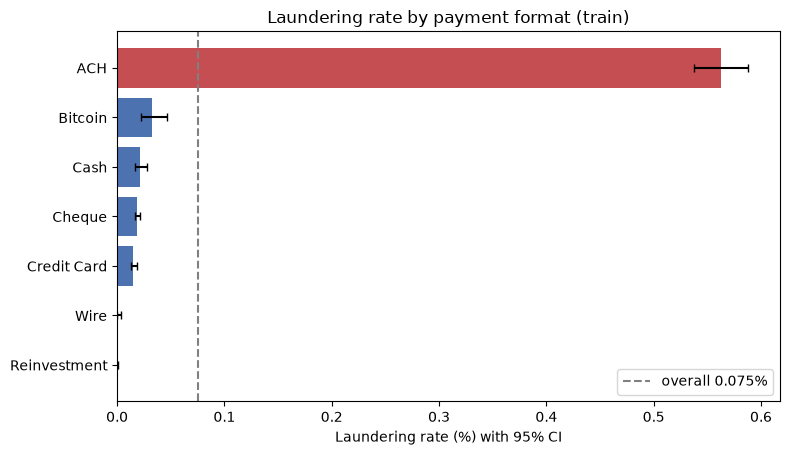

In [4]:
plot_rates(fmt, "Laundering rate by payment format (train)", highlight="ACH")

In [5]:
chi_square_test(train, "payment_format")

{'column': 'payment_format',
 'chi2': 12025.7,
 'dof': 6,
 'p_value': 0.0,
 'cramers_v': 0.0628,
 'min_expected_count': 65.7,
 'n': 3046861}

,transactions,laundering,rate_%,ci_low_%,ci_high_%,share_of_laundering_%,lift
payment_currency,,,,,,,
Saudi Riyal,52987,137,0.2586,0.2188,0.3055,5.9643,3.4296
Canadian Dollar,83749,73,0.0872,0.0693,0.1096,3.1781,1.1562
Rupee,114097,91,0.0798,0.0650,0.0979,3.9617,1.0579
Euro,702661,557,0.0793,0.0730,0.0861,24.2490,1.0515
Yuan,128298,100,0.0779,0.0641,0.0948,4.3535,1.0339
US Dollar,1137105,869,0.0764,0.0715,0.0817,37.8320,1.0137
Ruble,92881,68,0.0732,0.0578,0.0928,2.9604,0.9711
Brazil Real,42287,29,0.0686,0.0478,0.0985,1.2625,0.9097
UK Pound,108201,69,0.0638,0.0504,0.0807,3.0039,0.8459


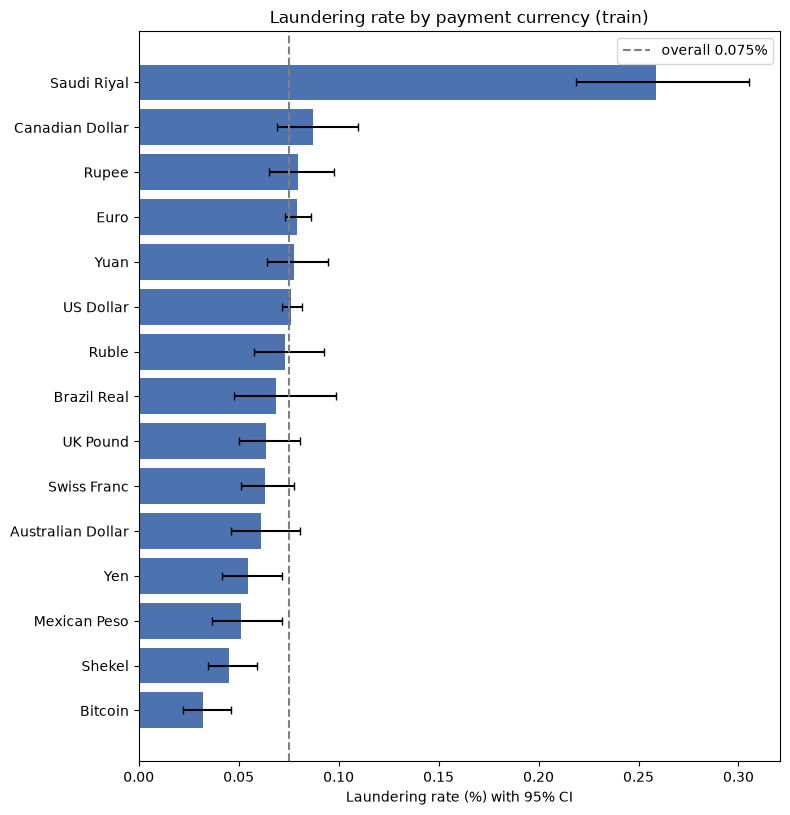

In [6]:
cur = rate_table(train, "payment_currency")
display(cur)
plot_rates(cur, "Laundering rate by payment currency (train)")

,transactions,laundering,rate_%,ci_low_%,ci_high_%,share_of_laundering_%,lift
same_bank,,,,,,,
False,2443247,2261,0.0925,0.0888,0.0964,98.4327,1.2275
True,603614,36,0.0060,0.0043,0.0083,1.5673,0.0791


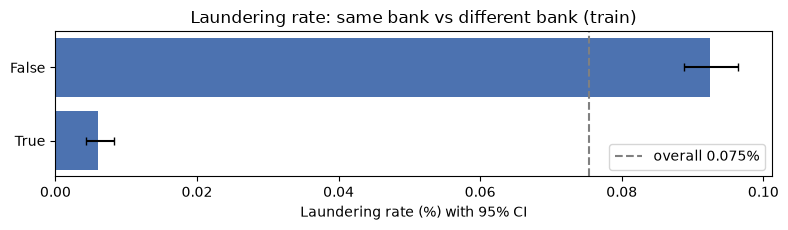

In [7]:
same = rate_table(train, "same_bank")
display(same)
plot_rates(same, "Laundering rate: same bank vs different bank (train)")

In [8]:
tests = pd.DataFrame(
    [chi_square_test(train, c) for c in ["payment_format", "payment_currency", "same_bank"]]
).set_index("column")
tests

,chi2,dof,p_value,cramers_v,min_expected_count,n
column,,,,,,
payment_format,12025.7,6,0.000000e+00,0.0628,65.7,3046861
payment_currency,292.8,14,3.772291e-54,0.0098,31.9,3046861
same_bank,480.5,1,1.695774e-106,0.0126,455.1,3046861


In [9]:
pd.crosstab(
    train["payment_format"] == "Bitcoin",
    train["payment_currency"] == "Bitcoin",
    rownames=["format is Bitcoin"], colnames=["currency is Bitcoin"],
)

currency is Bitcoin,False,True
format is Bitcoin,,
False,2959645,30
True,43,87143


In [10]:
check = train.assign(is_ach=train["payment_format"] == "ACH").groupby("payment_currency", observed=True).agg(
    ach_share_pct=("is_ach", lambda s: round(100 * s.mean(), 1)),
    rate_if_ach_pct=("is_laundering", lambda s: round(100 * s[train.loc[s.index, "payment_format"] == "ACH"].mean(), 4)),
    rate_if_not_ach_pct=("is_laundering", lambda s: round(100 * s[train.loc[s.index, "payment_format"] != "ACH"].mean(), 4)),
)
check.sort_values("ach_share_pct", ascending=False)

,ach_share_pct,rate_if_ach_pct,rate_if_not_ach_pct
payment_currency,,,
Yuan,14.2,0.4672,0.0136
US Dollar,11.9,0.5389,0.0141
UK Pound,11.5,0.4590,0.0125
Euro,11.4,0.5718,0.0161
Canadian Dollar,11.2,0.6833,0.0121
Yen,11.0,0.3914,0.0133
Rupee,10.9,0.6365,0.0118
Australian Dollar,10.5,0.4908,0.0109
Brazil Real,10.4,0.4764,0.0211


## What I found (train only)
- **ACH is the dominant signal.** ACH is 11% of payments but 83% of laundering (1,905 of 2,297). Its laundering rate is 0.56% (95% CI 0.54–0.59%), 7.5× the overall rate of 0.075%.
- **Wire and Reinvestment contain no laundering in train.** Models may learn these formats as "always safe", which is a quirk of the synthetic data rather than real-world behaviour.
- **Format is significantly linked to laundering** (χ² = 12,026, df = 6, p < 0.001). Cramér's V is only 0.063 because laundering is so rare; for a rare outcome the lift is the more meaningful measure of strength.
- **Currency matters little** (Cramér's V = 0.010). Most currencies' intervals overlap the average. The exception is the Saudi Riyal (0.26%, lift 3.4), which accounts for only 6% of laundering.
- **98.4% of laundering is between different banks.** The cross-bank rate (0.093%) is about 15× the same-bank rate (0.006%).
- **The Bitcoin format and Bitcoin currency mark almost the same 87,143 rows,** so these two features largely duplicate each other.
- With 3 million rows every test is "significant", so effect sizes (lift, Cramér's V) are used to judge importance.